# Librerías y Funciones

In [2]:
import uproot as up
import awkward as ak
import matplotlib.pyplot as plt
import vector as vec
import numpy as np
import pandas as pd
import os
from pathlib import Path
from scipy import stats as st
from matplotlib.ticker import MultipleLocator, FuncFormatter
from matplotlib.colors import LogNorm

vec.register_awkward()

In [3]:
# Funciones

# Utilitary functions

def pi_formatter(x, pos):
    n = x / np.pi
    if np.isclose(n, 0):
        return r"$0$"
    if np.isclose(n, 1):
        return r"$\pi$"
    if np.isclose(n, -1):
        return r"$-\pi$"
    if n.is_integer():
        return rf"${int(n)}\pi$"
    return rf"${int(2*n)}\pi/2$"

def print_sample_info(Delphes, Energy_label, Gen_Events, Process, data_to_analyse, N_data):

    print("┌─────────────────────────────────────┐")
    print("│           SAMPLE INFORMATION        │")
    print("├─────────────────────────────────────┤")
    print(f"│ Delphes       : {Delphes:<20}│")
    print(f"│ Energy        : {Energy_label:<20}│")
    print(f"│ Gen. Events   : {Gen_Events:<20}│")
    print(f"│ Proc. Events  : {N_data:<20}│")
    print(f"│ Process       : {Process:<20}│")
    print("├─────────────────────────────────────┤")
    print(f"│ Dataset       : {data_to_analyse:<20}│")
    print("└─────────────────────────────────────┘")

def parse_events(s):
    s = s.strip().lower()
    mult = {"k": 1_000, "M": 1_000_000}
    if s[-1] in mult:
        return int(float(s[:-1]) * mult[s[-1]])
    return int(s)

def calculo_rangos(lim_inf, lim_sup, data):

    if type(data) == list:

        Gen_Events = sum(len(data_i) for data_i in data)

        debajo = sum(np.sum(data_i < lim_inf) for data_i in data)

        dentro = sum(
            np.sum((data_i >= lim_inf) & (data_i <= lim_sup))
            for data_i in data
        )

        encima = sum(np.sum(data_i > lim_sup) for data_i in data)

        p_debajo = 100 * debajo / Gen_Events
        p_dentro = 100 * dentro / Gen_Events
        p_encima = 100 * encima / Gen_Events

        return lim_inf, lim_sup, p_debajo, p_dentro, p_encima

    else:

        return print("Error: data debe ser una lista de arrays de datos.")

def vectors_buildup(data):
    jets = ak.zip({
        "pt": data["Jet.PT"],
        "eta": data["Jet.Eta"],
        "phi": data["Jet.Phi"],
        "mass": data["Jet.Mass"],
        'TauTag': data["Jet.TauTag"],
        'BTag': data["Jet.BTag"],
    }, with_name="Momentum4D")

    tracks = ak.zip({
        "pt": data["Track.PT"],
        "eta": data["Track.Eta"],
        "phi": data["Track.Phi"],
        "mass": data["Track.Mass"],
        "d0":  data["Track.D0"],  
        "dz":  data["Track.DZ"]
    }, with_name="Momentum4D")

    return jets, tracks

# Selection Functions

def MET_trigger(data, MET_lowerbond):

    MET_mask = ak.flatten(data["MissingET.MET"]) > MET_lowerbond

    return MET_mask

def preselection_cut(vec, Pt_lowerBond, Eta_absoluteBond):
    cinematic_mask = (vec.pt > Pt_lowerBond) & (abs(vec.eta) < Eta_absoluteBond)
    return cinematic_mask

def Selected_data(data, MET_LB, PT_LB_jets, Eta_AB_jets, PT_LB_tracks, Eta_AB_tracks):

    MET_mask = MET_trigger(data, MET_LB)

    data_selected = data[MET_mask]

    # Construyo los jets, con su cuadrivector y los BTag y tautag

    jets, tracks = vectors_buildup(data_selected)

    jets_preselected = preselection_cut(jets, PT_LB_jets, Eta_AB_jets)
    tracks_preselected = preselection_cut(tracks, PT_LB_tracks, Eta_AB_tracks)

    jets_select, tracks_select = jets[jets_preselected], tracks[tracks_preselected]

    return jets_select, tracks_select

def Taus_and_bjets(jets):
    taus = jets[(jets['TauTag'] == 1) & (jets['BTag'] == 0)]
    bjets = jets[(jets['TauTag'] == 0) & (jets['BTag'] == 1)]

    N_events = len(ak.sum(jets, axis=1))
    N_taus = ak.num(taus, axis=1)
    N_bjets = ak.num(bjets, axis=1)

    return taus, bjets, N_events, N_taus, N_bjets

def kinematic_hierarchical_order(taus, bjets):
    mask  = (ak.num(taus) >= 2) & (ak.num(bjets) >= 2)
    taus_cut, bjets_cut = taus[mask], bjets[mask]
    tau1, tau2 = taus_cut[:,0], taus_cut[:,1]
    b1, b2     = bjets_cut[:,0], bjets_cut[:,1]
    return tau1, tau2, b1, b2, taus_cut, bjets_cut

def PT_and_IM_of_products(tau1, tau2, b1, b2):
    
    h_tautau_vec = tau1+tau2
    h_bb_vec = b1+b2
    
    M_tautau = h_tautau_vec.mass
    M_bb     = h_bb_vec.mass
    M_hh     = (tau1+tau2+b1+b2).mass

    PT_tautau = h_tautau_vec.pt
    PT_bb     = h_bb_vec.pt
    PT_hh     = (tau1+tau2+b1+b2).pt

    tuple_tautau = (M_tautau, PT_tautau)
    tuple_bb = (M_bb, PT_bb)
    tuple_hh = (M_hh, PT_hh)

    return tuple_tautau, tuple_bb, tuple_hh

# Data

In [22]:
saving_path = '/home/usuario/VSCode/diHiggs-Project/RecAnalysis'

# MET Selection

MET_LowerBond = 0     # GeV

# Jets preselection cuts
Pre_PT_jet = 20       # GeV
Pre_eta_jet = 2.5

# Tracks preselection cuts
Pre_PT_track = 0      # GeV
Pre_eta_track = 2.5

Delphes = "HL-LHC"
Energy_label = "14TeV"
BenchMark = "Pruebas"
process = "gg-hhj"

data_to_analyse = f"{Delphes}_{Energy_label}_{BenchMark}_{process}"

extracted_keys = ["Particle.PID", "Particle.Status",
                        "Particle.PT", "Particle.Eta", "Particle.Phi", "Particle.Mass",
                        "Track.PT", "Track.Eta", "Track.Phi", "Track.Charge", "MissingET.MET"]

rutas = {
    "signal": "/run/media/usuario/0012-D687/plusjet/output_ggHH_bbtata_BP1_80_0_delphes_events.root",
}


def data_loader(rutas):
    return {key: up.concatenate(f"{path}:Delphes", extracted_keys)
            for key, path in rutas.items()}

all_data = data_loader(rutas)

N_data = len(all_data['signal'])

folder_path = f'/home/usuario/VSCode/diHiggs-Project/RecAnalysis/{data_to_analyse}'

print_sample_info(Delphes, Energy_label, BenchMark, process, data_to_analyse, N_data)

os.makedirs(folder_path, exist_ok=True)

┌─────────────────────────────────────┐
│           SAMPLE INFORMATION        │
├─────────────────────────────────────┤
│ Delphes       : HL-LHC              │
│ Energy        : 14TeV               │
│ Gen. Events   : Pruebas             │
│ Proc. Events  : 9736                │
│ Process       : gg-hhj              │
├─────────────────────────────────────┤
│ Dataset       : HL-LHC_14TeV_Pruebas_gg-hhj│
└─────────────────────────────────────┘


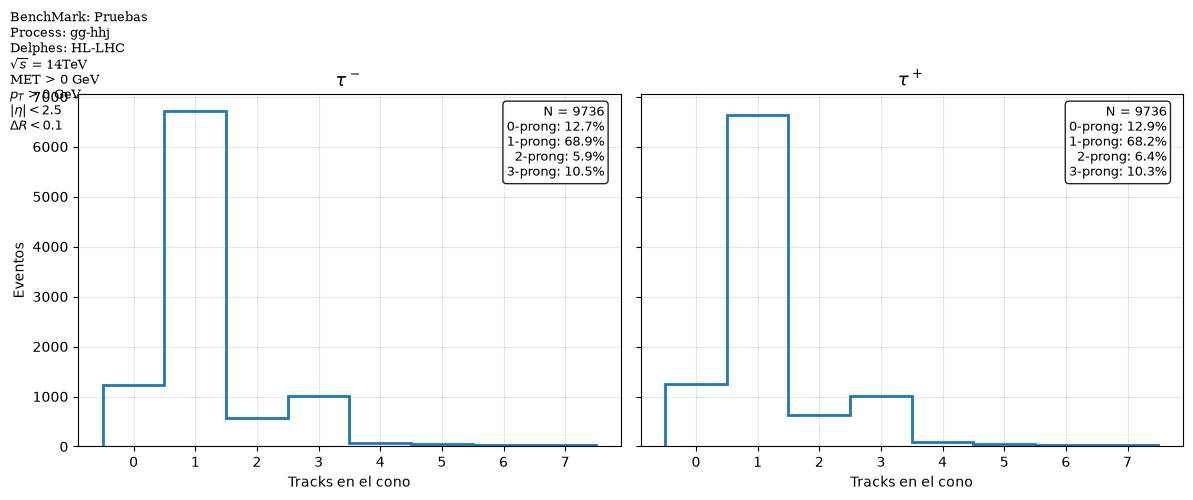

In [ ]:
# ---- parámetros ----
DR_TAU   = 0.1    # radio del cono alrededor del tau truth
PT_TRACK = 1    # umbral mínimo de pT de los tracks [GeV]

signal_data = all_data['signal']

# ---- nivel truth: partículas del generador ----
gen = ak.zip({"pt": signal_data["Particle.PT"], "eta": signal_data["Particle.Eta"],
              "phi": signal_data["Particle.Phi"], "mass": signal_data["Particle.Mass"],
              "pid": signal_data["Particle.PID"], "status": signal_data["Particle.Status"]},
             with_name="Momentum4D")

# ---- nivel reco: tracks ----
# Track no trae Mass; se pone cero para que vector arme el cuadrivector
tracks = ak.zip({"pt": signal_data["Track.PT"], "eta": signal_data["Track.Eta"],
                 "phi": signal_data["Track.Phi"],
                 "mass": ak.zeros_like(signal_data["Track.PT"]),
                 "charge": signal_data["Track.Charge"]},
                with_name="Momentum4D")
tracks = tracks[tracks.pt > PT_TRACK]

# ---- taus truth: última copia de cada carga ----
# status 2 = partícula que decayó;  PID +15 = tau-,  -15 = tau+
t2     = gen[(abs(gen.pid) == 15) & (gen.status == 2)]
tm_all = t2[t2.pid > 0]
tp_all = t2[t2.pid < 0]

ok = (ak.num(tm_all, axis=1) >= 1) & (ak.num(tp_all, axis=1) >= 1)

taum      = tm_all[ok][:, -1]
taup      = tp_all[ok][:, -1]
tracks_ev = tracks[ok]

# ---- matching geométrico ----
en_taum = taum.deltaR(tracks_ev) < DR_TAU
en_taup = taup.deltaR(tracks_ev) < DR_TAU

tracks_taum = tracks_ev[en_taum]            # tracks del tau-
tracks_taup = tracks_ev[en_taup]            # tracks del tau+
tracks_taus = tracks_ev[en_taum | en_taup]  # de cualquiera de los dos

# ---- diagnósticos ----
n_m = ak.num(tracks_taum, axis=1)
n_p = ak.num(tracks_taup, axis=1)
q_m = ak.sum(tracks_taum.charge, axis=1)

# Plots

bines = np.arange(-0.5, 8.5, 1)   # bordes en medios enteros: una barra por valor

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, n, lab in [(axes[0], n_m, r"$\tau^-$"), (axes[1], n_p, r"$\tau^+$")]:
    n_np = ak.to_numpy(n)
    ax.hist(n_np, bins=bines, histtype="step", linewidth=2, color="tab:blue")
    ax.set_title(lab, fontsize=13)
    ax.set_xlabel("Tracks en el cono")
    ax.set_xticks(range(0, 8))
    ax.grid(alpha=0.3)
    ax.text(0.97, 0.97,
            f"N = {len(n_np)}\n"
            f"0-prong: {100*(n_np==0).mean():.1f}%\n"
            f"1-prong: {100*(n_np==1).mean():.1f}%\n"
            f"2-prong: {100*(n_np==2).mean():.1f}%\n"
            f"3-prong: {100*(n_np==3).mean():.1f}%",
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))

axes[0].set_ylabel("Eventos")

fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(f"Prongs_truth_matched.png", dpi=300)
plt.show()